<a href="https://colab.research.google.com/github/Manu-oq/sic_ia_2026/blob/main/ejercicios_estudiantes/Grupo3C__clase_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Este grupo se conforma por: Nicolas, Noemi Calabuig, Catalina Caris, Manuel Ortega

# 3C · Algoritmos de conjunto

**Láminas:** 378 al final

## Resumen del Subgrupo 3C: Algoritmos de Conjunto (Ensemble Learning)

### 1. ¿Qué es el Aprendizaje en Conjunto?
* **Principio:** Combinar múltiples modelos imperfectos pero diversos (aprendices débiles o *weak learners*) para construir un modelo de alta precisión (aprendiz fuerte o *strong learner*).
* **Analogía:** La Junta Médica. Ante un diagnóstico difícil, no confiamos en la opinión de un solo médico; consultamos a varios especialistas y decidimos por consenso. Los errores individuales se cancelan entre sí.

### 2. Votación (VotingClassifier)
Combina modelos de algoritmos diferentes (ej. Regresión Logística + KNN + Árbol):
* **Votación Dura (Hard Voting):** Conteo de votos simple. Gana la clase con más votos por mayoría.
* **Votación Blanda (Soft Voting):** Se promedian las probabilidades estimadas por cada modelo. Es superior porque pondera la confianza y certeza de cada clasificador.

### 3. Bagging y Random Forest (Reducción de Varianza)
* **Bootstrap:** Muestreo aleatorio con reemplazo. Cada muestra contiene aprox. el 63.2% de datos únicos, dejando un 36.8% fuera (*Out-of-Bag*).
* **Bagging (Bootstrap Aggregating):** Entrena el mismo modelo (árboles) en paralelo sobre muestras bootstrap y promedia sus predicciones.
* **Random Forest:** Agrega selección aleatoria de variables (*Feature Bagging*) en cada división del árbol ($\sqrt{p}$).
  * *¿Por qué descorrelacionar los árboles?* Si una variable es dominante, un árbol solo la pondría siempre en la raíz. Al limitar las variables, obligamos a los árboles a buscar patrones diversos. Al promediar cientos de árboles diferentes, el sobreajuste desaparece.

### 4. Boosting (Reducción de Sesgo)
Entrenamiento en serie (secuencial): cada nuevo modelo se enfoca en corregir los errores cometidos por los modelos anteriores.
* **AdaBoost:** Pondera las instancias difíciles aumentando su peso para que el siguiente árbol las priorice.
* **Gradient Boosting:** Cada nuevo árbol entrena prediciendo los residuos (errores matemáticos) del ensamble anterior usando descenso de gradiente.
* **XGBoost y LightGBM:** Implementaciones industriales optimizadas para máxima velocidad y regularización.

### 5. Stacking (StackingClassifier)

Arquitectura en dos niveles que aprende a combinar las predicciones de distintos modelos:

* Modelos Base (Nivel 0): Varios modelos diversos (ej. Regresión Logística, KNN, Árbol) generan sus predicciones sobre los datos de entrada.

* Meta-Modelo (Nivel 1): Un modelo superior (generalmente Regresión Logística) toma las predicciones del Nivel 0 como sus variables de entrada y aprende a dar el veredicto final.

* Diferencia clave: A diferencia de la votación simple, el meta-modelo aprende en qué casos confiar más en un modelo base que en otro.

---

### 6. Comparativa Rápida: Bagging vs. Boosting vs Stacking

| Característica | Bagging (Random Forest) | Boosting (Gradient Boosting) | Stacking (StackingClassifier) |
| :--- | :--- | :--- | :--- |
| **Forma de entrenar** | En paralelo (independientes) | En serie (secuencial) | En dos niveles (base y meta-modelo) |
| **Meta matemática** | Reduce Varianza (evita sobreajuste) | Reduce Sesgo (aumenta capacidad) | Optimiza combinación de predicciones |
| **Modelos base** | Árboles profundos y complejos | Árboles cortos o 'tocones' (*stumps*) | Heterogéneos (modelos de distinto tipo) |
| **Hiperparámetros** | `n_estimators`, `max_features` | `n_estimators`, `learning_rate` | `estimators`, `final_estimator` |
---

### 6. Preguntas Clave de Cierre
1. **¿Diferencia entre votación dura y blanda?**
   * La dura suma votos simples; la blanda promedia las probabilidades estimadas de cada modelo, dando más peso a la certeza.
2. **¿Por qué Random Forest sobreajusta menos que un solo árbol?**
   * Porque combina y promedia cientos de árboles descorrelacionados (gracias al bootstrap y la selección aleatoria de variables), cancelando la varianza.
3. **¿En qué se diferencia el entrenamiento de Bagging y Boosting?**
   * Bagging entrena modelos independientes en paralelo para reducir varianza; Boosting entrena en serie donde cada nuevo modelo corrige los errores del anterior para reducir sesgo.

## Ejemplo propio del subgrupo 3C: Comparativa de Ensambles en Cáncer de Mama

=== EXACTITUD PROMEDIO EN VALIDACIÓN CRUZADA (5 pliegues) ===
1. Árbol Simple       : 0.9173 (91.73%)
2. Votación Blanda    : 0.9578 (95.78%)
3. Random Forest      : 0.9561 (95.61%)
4. AdaBoost           : 0.9772 (97.72%)
5. Gradient Boosting  : 0.9631 (96.31%)
6. Stacking           : 0.9772 (97.72%)


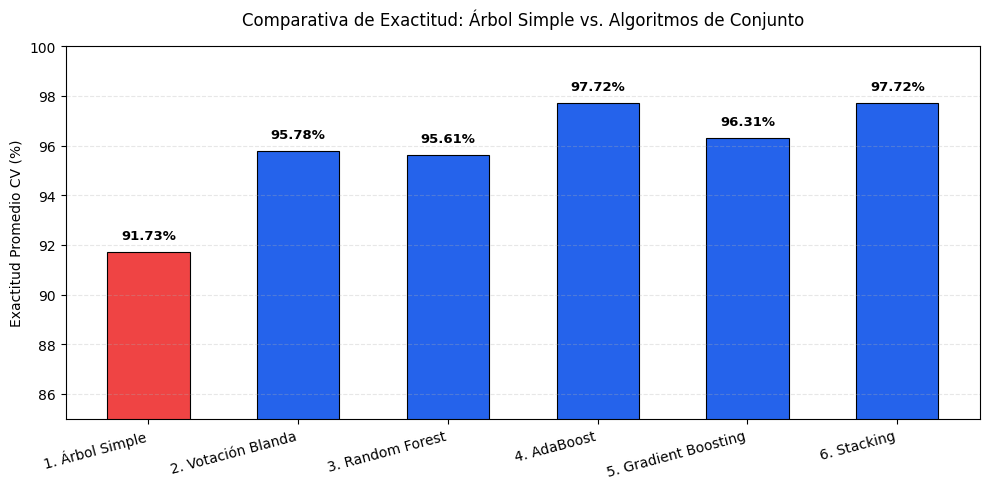

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 1. Cargar datos
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target

# 2. Definir modelos base
arbol = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
ada = AdaBoostClassifier(n_estimators=100, random_state=42)
gb = GradientBoostingClassifier(random_state=42)

votacion = VotingClassifier(
    estimators=[
        (
            "lr",
            make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        ),
        ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(5))),
        ("arbol", DecisionTreeClassifier(max_depth=4, random_state=42)),
    ],
    voting="soft",
)


modelos_base_stacking = [
    (
        "lr",
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    ),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(5))),
    ("arbol", DecisionTreeClassifier(max_depth=4, random_state=42)),
]

stacking = StackingClassifier(
    estimators=modelos_base_stacking,
    final_estimator=LogisticRegression(max_iter=1000),
)

# Diccionario completo con los 6 modelos a comparar
modelos = {
    "1. Árbol Simple": arbol,
    "2. Votación Blanda": votacion,
    "3. Random Forest": rf,
    "4. AdaBoost": ada,
    "5. Gradient Boosting": gb,
    "6. Stacking": stacking,
}

# 3. Evaluación con Validación Cruzada (5 pliegues)
print("=== EXACTITUD PROMEDIO EN VALIDACIÓN CRUZADA (5 pliegues) ===")
scores = {}
for nombre, m in modelos.items():
  s = cross_val_score(m, X, y, cv=5).mean()
  scores[nombre] = s
  print(f"{nombre:22s}: {s:.4f} ({s*100:.2f}%)")

# 4. Gráfico Comparativo de Exactitud entre todos los modelos
plt.figure(figsize=(10, 5))

nombres_modelos = list(scores.keys())
valores_exactitud = [s * 100 for s in scores.values()]  # Convertir a porcentaje

# Colores destacados (rojo para el árbol simple, azul para los ensambles)
colores = [
    "#EF4444" if "Árbol Simple" in m else "#2563EB" for m in nombres_modelos
]
barras = plt.bar(
    nombres_modelos,
    valores_exactitud,
    color=colores,
    width=0.55,
    edgecolor="black",
    linewidth=0.8,
)

# Añadir el valor del porcentaje arriba de cada barra
for barra in barras:
  yval = barra.get_height()
  plt.text(
      barra.get_x() + barra.get_width() / 2.0,
      yval + 0.4,
      f"{yval:.2f}%",
      ha="center",
      va="bottom",
      fontsize=9.5,
      fontweight="bold",
  )

plt.title(
    "Comparativa de Exactitud: Árbol Simple vs. Algoritmos de Conjunto",
    fontsize=12,
    pad=15,
)
plt.ylabel("Exactitud Promedio CV (%)")
plt.ylim(85, 100)  # Zoom entre 85% y 100% para apreciar las diferencias
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Ejercicio para la clase (3C)

Crea un modelo de ensamble `RandomForestClassifier` con exactamente `n_estimators=150` y semilla `random_state=42`. Entrénalo con los datos de entrenamiento `X_tr` e `y_tr`. Luego, calcula su exactitud en el conjunto de prueba (`X_te`, `y_te`) y guarda el resultado redondeado a 3 decimales con `round(..., 3)` en la variable `respuesta_3c`.

In [ ]:
# === EJERCICIO 3C Y VERIFICACIÓN ===
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1. Cargar y dividir datos
X_ex, y_ex = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X_ex, y_ex, test_size=0.3, random_state=42, stratify=y_ex
)

# 2. Entrenar el ensamble (Random Forest)
modelo_rf = RandomForestClassifier(n_estimators=150, random_state=42)
modelo_rf.fit(X_tr, y_tr)

# 3. Calcular exactitud en porcentaje
acc = modelo_rf.score(X_te, y_te) * 100
respuesta_3c = round(acc, 2)

### Verificación del ejercicio 3C

In [ ]:
# 4. Verificación
if respuesta_3c > 90:
  print(
      f"¡Excelente! El Random Forest obtuvo un {respuesta_3c}% de exactitud en"
      " prueba."
  )
else:
  print(f"Rendimiento actual: {respuesta_3c}%. Revisa la configuración.")

¡Excelente! El Random Forest obtuvo un 94.15% de exactitud en prueba.
